In [18]:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

In [9]:
data = pd.read_csv("../data/student_mental_health_clean.csv")

X = data.drop(columns=["Student_ID", "Mental_Health_Risk"])
y = data["Mental_Health_Risk"]

In [10]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [11]:
print("Train :", X_train.shape)
print("Validation :", X_val.shape)
print("Test :", X_test.shape)

Train : (1400, 15)
Validation : (300, 15)
Test : (300, 15)


In [12]:
preprocessing = joblib.load("../models/preprocessing.joblib")

In [13]:
lr_pipline = Pipeline([
    ("preprocessing",preprocessing),
    ("model",LogisticRegression(max_iter=1000))
])

lr_pipline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['Age','Gender','Year_of_Study',...,'Part_Time_Job','Diet_Quality', 'Previous_Mental_Health_History']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of 

In [ ]:
# lr
y_val_pred = lr_pipline.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_val_pred))

print(classification_report(y_val, y_val_pred))

Accuracy: 0.7633333333333333
              precision    recall  f1-score   support

        High       0.84      0.81      0.83       102
         Low       0.80      0.83      0.82        99
      Medium       0.65      0.65      0.65        99

    accuracy                           0.76       300
   macro avg       0.76      0.76      0.76       300
weighted avg       0.76      0.76      0.76       300



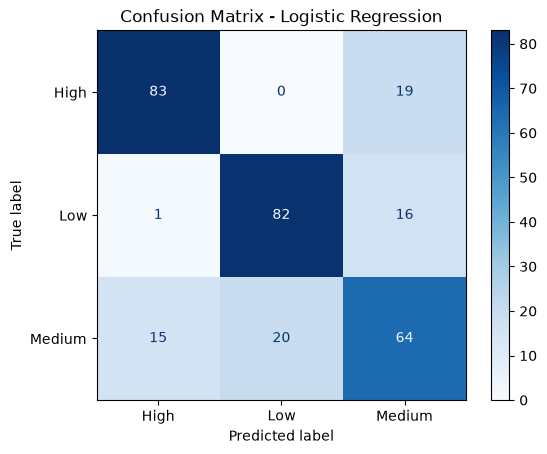

In [19]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    cmap="Blues"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [26]:
from sklearn.ensemble import RandomForestClassifier

rf_pipline = Pipeline([
    ("preprocessing",preprocessing),
    ("model",RandomForestClassifier(random_state=42))
])

rf_pipline.fit(X_train,y_train)

y_val_pred_rf = rf_pipline.predict(X_val)

print("Accuracy : ",accuracy_score(y_val,y_val_pred_rf))
print(classification_report(y_val,y_val_pred_rf))

Accuracy :  0.69
              precision    recall  f1-score   support

        High       0.72      0.75      0.73       102
         Low       0.77      0.82      0.79        99
      Medium       0.56      0.51      0.53        99

    accuracy                           0.69       300
   macro avg       0.68      0.69      0.69       300
weighted avg       0.68      0.69      0.69       300



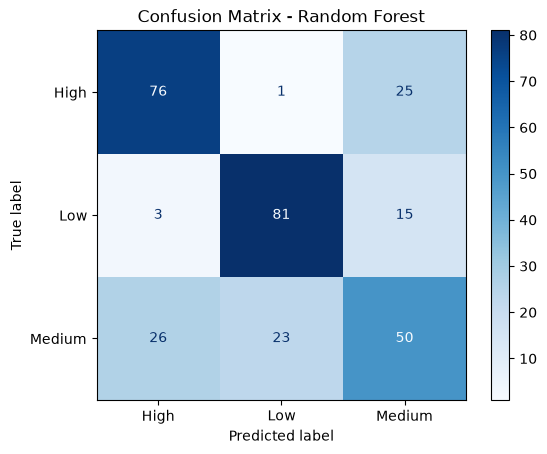

In [32]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_rf,
    cmap="Blues"
)

plt.title("Confusion Matrix - Random Forest")
plt.show()

In [28]:
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("model", SVC())
])

svm_pipeline.fit(X_train, y_train)

y_val_pred_svm = svm_pipeline.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_val_pred_svm))
print(classification_report(y_val, y_val_pred_svm))

Accuracy: 0.74
              precision    recall  f1-score   support

        High       0.81      0.77      0.79       102
         Low       0.78      0.83      0.80        99
      Medium       0.63      0.62      0.62        99

    accuracy                           0.74       300
   macro avg       0.74      0.74      0.74       300
weighted avg       0.74      0.74      0.74       300



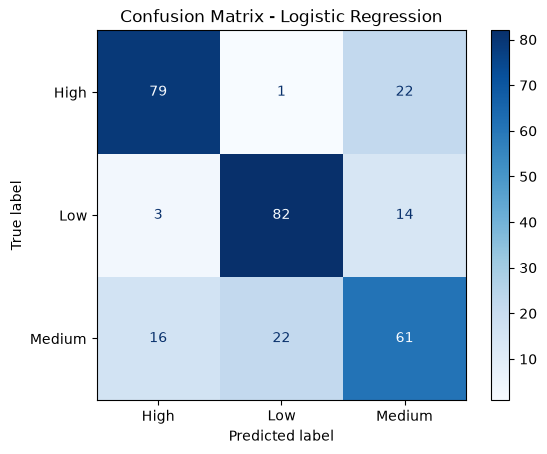

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_svm,
    cmap="Blues"
)

plt.title("Confusion Matrix - Svm")
plt.show()

In [ ]:
# optimisation
from sklearn.model_selection import GridSearchCV

lr_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("model", LogisticRegression(max_iter=1000))
])

param_grid_lr = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

grid_lr = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid_lr,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

grid_lr.fit(X_train, y_train)

print("Best Parameters:", grid_lr.best_params_)
print("Best CV Score:", grid_lr.best_score_)

Best Parameters: {'model__C': 100}
Best CV Score: 0.7503565439049685


In [34]:
best_lr = grid_lr.best_estimator_
y_val_pred_lr_tuned = best_lr.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_val_pred_lr_tuned))
print(classification_report(y_val, y_val_pred_lr_tuned))

Accuracy: 0.7666666666666667
              precision    recall  f1-score   support

        High       0.84      0.81      0.83       102
         Low       0.81      0.83      0.82        99
      Medium       0.65      0.66      0.65        99

    accuracy                           0.77       300
   macro avg       0.77      0.77      0.77       300
weighted avg       0.77      0.77      0.77       300



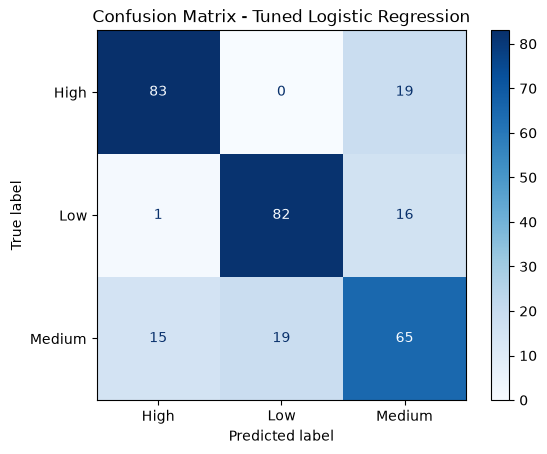

In [35]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_lr_tuned,
    cmap="Blues"
)

plt.title("Confusion Matrix - Tuned Logistic Regression")
plt.show()

In [36]:
# svm
svm_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("model", SVC())
])

param_grid_svm = {
    "model__C": [0.1, 1, 10, 100],
    "model__kernel": ["linear", "rbf"],
    "model__gamma": ["scale", "auto"]
}

grid_svm = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid_svm,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

grid_svm.fit(X_train, y_train)

print("Best Parameters:", grid_svm.best_params_)
print("Best CV Score:", grid_svm.best_score_)

Best Parameters: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best CV Score: 0.7475146738721982


Accuracy: 0.77
              precision    recall  f1-score   support

        High       0.83      0.83      0.83       102
         Low       0.81      0.83      0.82        99
      Medium       0.66      0.65      0.65        99

    accuracy                           0.77       300
   macro avg       0.77      0.77      0.77       300
weighted avg       0.77      0.77      0.77       300



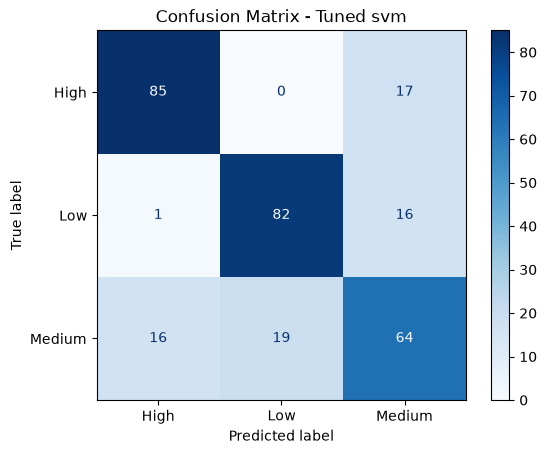

In [38]:
best_svm = grid_svm.best_estimator_
y_val_pred_svm_tuned = best_svm.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_val_pred_svm_tuned))
print(classification_report(y_val, y_val_pred_svm_tuned))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_svm_tuned,
    cmap="Blues"
)

plt.title("Confusion Matrix - Tuned svm")
plt.show()

In [39]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("model", RandomForestClassifier(random_state=42))
])

param_grid_rf = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

grid_rf = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_rf,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print("Best Parameters:", grid_rf.best_params_)
print("Best CV Score:", grid_rf.best_score_)

Best Parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__min_samples_split': 10, 'model__n_estimators': 200}
Best CV Score: 0.6870046438533481


Accuracy: 0.7133333333333334
              precision    recall  f1-score   support

        High       0.75      0.75      0.75       102
         Low       0.78      0.84      0.81        99
      Medium       0.60      0.56      0.58        99

    accuracy                           0.71       300
   macro avg       0.71      0.71      0.71       300
weighted avg       0.71      0.71      0.71       300



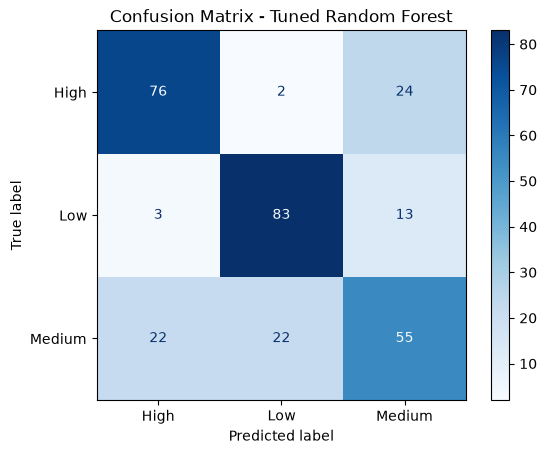

In [41]:
best_rf = grid_rf.best_estimator_
y_val_pred_rf_tuned = best_rf.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_val_pred_rf_tuned))
print(classification_report(y_val, y_val_pred_rf_tuned))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_rf_tuned,
    cmap="Blues"
)

plt.title("Confusion Matrix - Tuned Random Forest")
plt.show()

Test Accuracy: 0.7566666666666667
              precision    recall  f1-score   support

        High       0.81      0.80      0.81       102
         Low       0.81      0.86      0.83        99
      Medium       0.64      0.61      0.62        99

    accuracy                           0.76       300
   macro avg       0.75      0.76      0.75       300
weighted avg       0.75      0.76      0.75       300



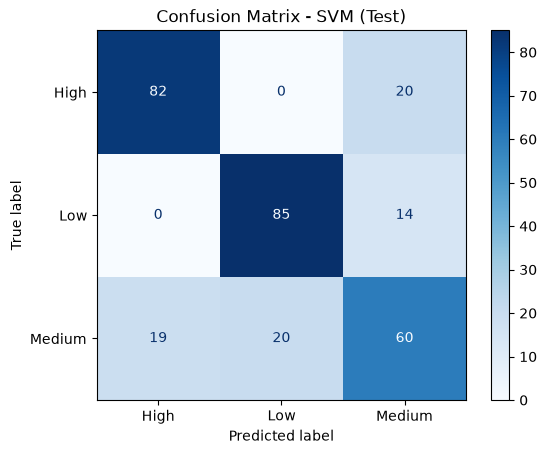

In [ ]:
# évaluation finale (test)

y_test_pred_svm = best_svm.predict(X_test)
print("Test Accuracy:", accuracy_score(y_test, y_test_pred_svm))

print(classification_report(y_test,y_test_pred_svm))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_svm,
    cmap="Blues"
)

plt.title("Confusion Matrix - SVM (Test)")
plt.show()

Test Accuracy: 0.76
              precision    recall  f1-score   support

        High       0.81      0.80      0.81       102
         Low       0.81      0.87      0.84        99
      Medium       0.65      0.61      0.62        99

    accuracy                           0.76       300
   macro avg       0.76      0.76      0.76       300
weighted avg       0.76      0.76      0.76       300



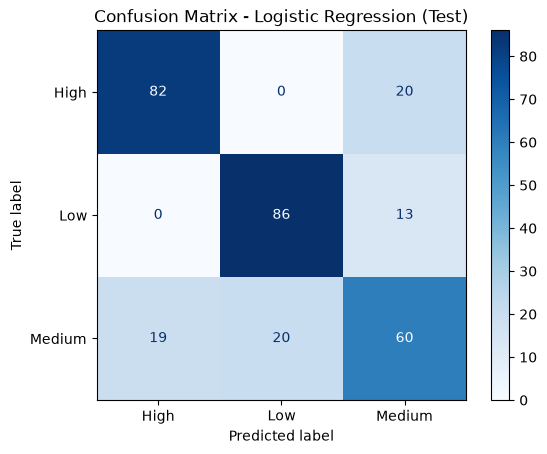

In [43]:
y_test_pred_lr = best_lr.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_test_pred_lr))

print(classification_report(
    y_test,
    y_test_pred_lr
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_lr,
    cmap="Blues"
)

plt.title("Confusion Matrix - Logistic Regression (Test)")
plt.show()

Test Accuracy: 0.7
              precision    recall  f1-score   support

        High       0.76      0.73      0.74       102
         Low       0.74      0.87      0.80        99
      Medium       0.59      0.51      0.54        99

    accuracy                           0.70       300
   macro avg       0.69      0.70      0.69       300
weighted avg       0.69      0.70      0.69       300



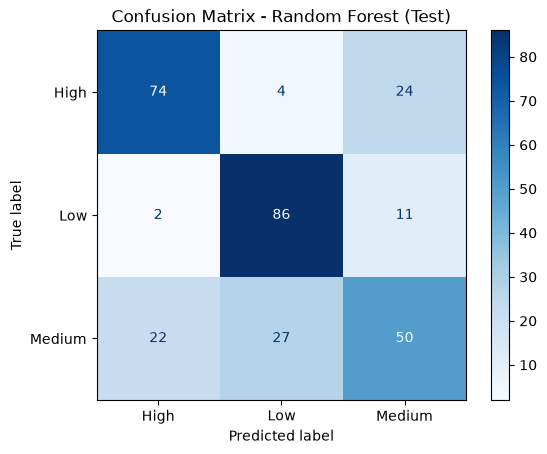

In [44]:
# rf
y_test_pred_rf = best_rf.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_test_pred_rf))

print(classification_report(
    y_test,
    y_test_pred_rf
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_rf,
    cmap="Blues"
)

plt.title("Confusion Matrix - Random Forest (Test)")
plt.show()

In [45]:
import joblib

final_model = grid_lr.best_estimator_

joblib.dump(final_model, "../models/mental_health_model.pkl")

['../models/mental_health_model.pkl']

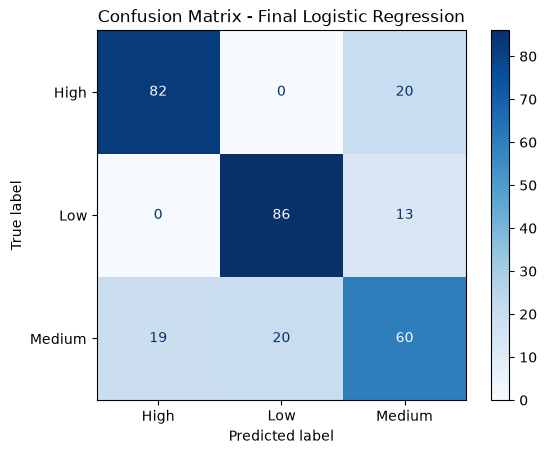

In [48]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_lr,
    cmap="Blues"
)

plt.title("Confusion Matrix - Final Logistic Regression")
plt.show()

In [55]:
errors = X_test.copy()

errors["Actual"] = y_test
errors["Predicted"] = y_test_pred_lr

errors = errors[errors["Actual"] != errors["Predicted"]]

print("Nombre d'erreurs :", len(errors))
display(errors)

Nombre d'erreurs : 72


,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Actual,Predicted
274,19,Female,2,6.9,19.8,2.49,3.8,6.7,High,2.8,4.5,79.5,No,Average,Yes,Medium,Low
751,18,Female,1,5.8,18.1,2.87,6.1,10.2,Moderate,NaN,6.9,89.3,No,Good,No,High,Medium
670,24,Female,1,NaN,15.8,2.62,5.6,8.4,Moderate,4.1,4.4,84.1,Yes,Average,No,Low,Medium
1136,24,Female,1,5.5,18.5,2.47,7.1,9.7,High,6.6,6.4,77.2,Yes,Good,No,Medium,High
720,22,Female,4,5.9,21.7,2.23,6.1,9.0,Moderate,3.1,9.4,86.5,Yes,Poor,No,Low,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
911,21,Female,5,6.3,25.6,2.60,6.9,8.3,Moderate,4.6,6.2,84.5,No,Good,No,Medium,Low
524,19,Male,2,5.7,17.1,2.71,8.2,9.9,Moderate,5.8,6.2,89.3,No,Good,No,Low,Medium
758,19,Male,2,NaN,16.9,2.94,6.1,6.1,Low,3.8,5.2,89.2,Yes,Poor,Yes,Medium,High
1889,21,Female,1,6.7,14.8,2.24,7.0,9.7,Moderate,6.5,8.6,89.3,Yes,Good,Yes,Medium,High


Le modèle a correctement classé 76 % des étudiants. Cependant, il a commis 72 erreurs de prédiction, soit 24 % des observations.


Le modèle rencontre davantage de difficultés à identifier correctement les étudiants appartenant à la catégorie Medium, car il a du mal à les distinguer des catégories Low et High.

In [58]:
import pandas as pd

results = pd.read_csv("../data/mental_health_predictions.csv")

print(results.head())
print(results.shape)
print(results["Predicted_Risk"].value_counts())

  Student_ID Actual_Risk Predicted_Risk
0    STU0001        High           High
1    STU0002      Medium           High
2    STU0003      Medium         Medium
3    STU0004        High           High
4    STU0005      Medium         Medium
(2000, 3)
Predicted_Risk
High      670
Medium    665
Low       665
Name: count, dtype: int64


In [59]:
errors = results[
    results["Actual_Risk"] != results["Predicted_Risk"]
]

print("Number of errors:", len(errors))
print(errors.head(10))

Number of errors: 463
   Student_ID Actual_Risk Predicted_Risk
1     STU0002      Medium           High
5     STU0006      Medium           High
14    STU0015        High         Medium
15    STU0016      Medium           High
16    STU0017      Medium            Low
21    STU0022      Medium           High
23    STU0024         Low         Medium
25    STU0026        High         Medium
30    STU0031      Medium           High
34    STU0035      Medium           High
